# Lab: Decision Trees (Chapter 6)
**CIS — Machine Learning | Graduate Section**

In this lab you start from **working code** and then **modify or extend it**. Each part has:
- a starter cell that already runs,
- a **TODO** that asks you to change or add something,
- a short **reflection question** to answer in a markdown cell (2–4 sentences).

**Submit:** your completed notebook (`.ipynb`) with all cells run.

**Estimated time:** 60–90 minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score

np.random.seed(42)

## Part 1: Train and visualize a tree (Iris)
The code below trains the tree from the slides (petal length and width, `max_depth=2`) and draws it.

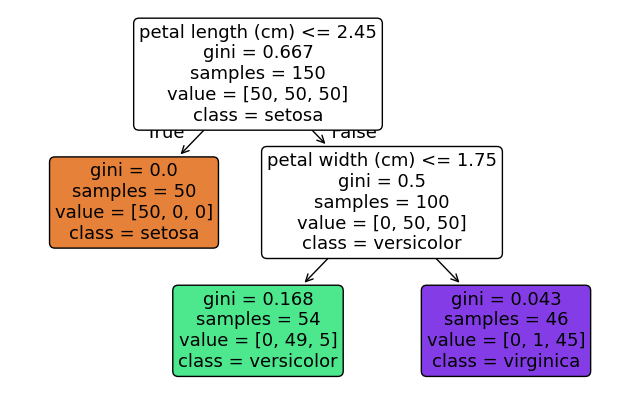

Depth: 2 | Leaves: 3


In [2]:
iris = load_iris()
X = iris.data[:, 2:]          # petal length, petal width
y = iris.target

tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

plt.figure(figsize=(8, 5))
plot_tree(tree_clf, feature_names=iris.feature_names[2:],
          class_names=iris.target_names, rounded=True, filled=True)
plt.show()

print("Depth:", tree_clf.get_depth(), "| Leaves:", tree_clf.get_n_leaves())

### TODO 1
1. Change `max_depth` to **3** and re-run. Record the new depth and number of leaves.
2. Now remove `max_depth` entirely (unlimited). What depth does the tree reach, and are all leaves pure (gini = 0)?

**Reflection:** Why does the tree stop growing even when `max_depth` is not set?

max_depth=3  -> Depth: 3 | Leaves: 5


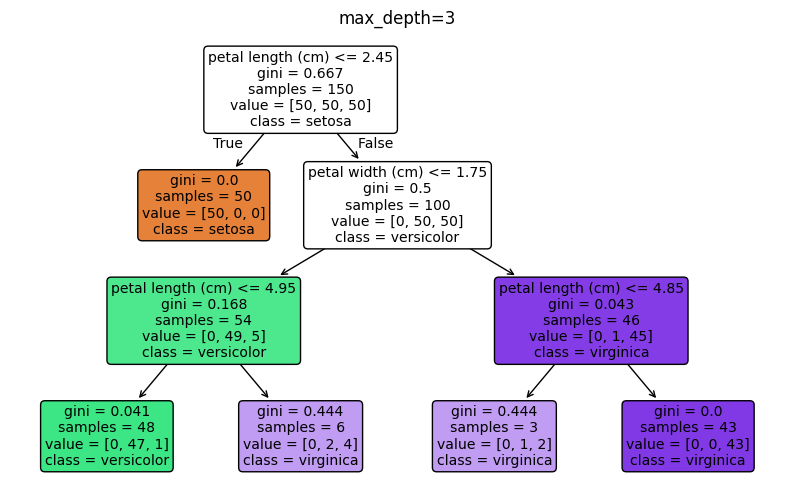

unlimited    -> Depth: 5 | Leaves: 8


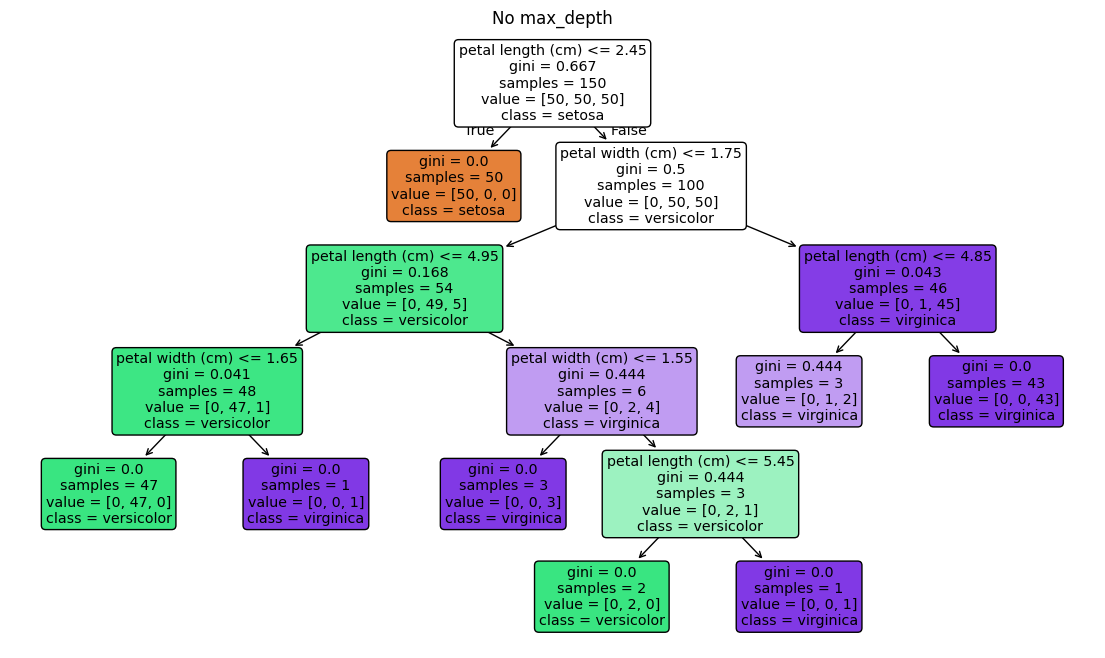

Leaf gini values: [0.    0.    0.    0.    0.    0.    0.444 0.   ]
All leaves pure? False
Samples in the impure leaf (petal length, petal width, class):
   [4.8 1.8] versicolor
   [4.8 1.8] virginica
   [4.8 1.8] virginica


In [3]:
# TODO 1: your code here
# 1) max_depth = 3
tree_d3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X, y)
print("max_depth=3  -> Depth:", tree_d3.get_depth(), "| Leaves:", tree_d3.get_n_leaves())

plt.figure(figsize=(10, 6))
plot_tree(tree_d3, feature_names=iris.feature_names[2:],
          class_names=iris.target_names, rounded=True, filled=True)
plt.title("max_depth=3")
plt.show()

# 2) No max_depth (unlimited)
tree_full = DecisionTreeClassifier(random_state=42).fit(X, y)
print("unlimited    -> Depth:", tree_full.get_depth(), "| Leaves:", tree_full.get_n_leaves())

plt.figure(figsize=(14, 8))
plot_tree(tree_full, feature_names=iris.feature_names[2:],
          class_names=iris.target_names, rounded=True, filled=True)
plt.title("No max_depth")
plt.show()

# Are all leaves pure?
is_leaf = tree_full.tree_.children_left == -1
leaf_gini = tree_full.tree_.impurity[is_leaf]
leaf_vals = tree_full.tree_.value[is_leaf]
print("Leaf gini values:", leaf_gini.round(3))
print("All leaves pure?", np.all(leaf_gini == 0))

# Look at the impure leaf: which samples are in it?
impure_leaf_id = np.where(is_leaf)[0][leaf_gini > 0]
in_leaf = np.isin(tree_full.apply(X), impure_leaf_id)
print("Samples in the impure leaf (petal length, petal width, class):")
for xi, yi in zip(X[in_leaf], y[in_leaf]):
    print("  ", xi, iris.target_names[yi])

*Your reflection:*

With `max_depth=3` the tree has depth 3 and 5 leaves. With no `max_depth`, it grows to depth 5 with 8 leaves, but **not every leaf is pure**: one leaf still has gini ≈ 0.444. That leaf holds flowers with the exact same petal measurements (e.g., 4.8 cm × 1.8 cm) but different species, so no split on these two features can separate them. The tree stops growing when a node is pure **or** when no split can reduce impurity any further (and it also respects defaults like `min_samples_split=2`), so it stops even without a depth limit.

## Part 2: Predictions and class probabilities
The tree from Part 1 (use `max_depth=2`) predicts a flower with petals 5 cm long and 1.5 cm wide.

In [4]:
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)

flower = [[5, 1.5]]
print("Probabilities:", tree_clf.predict_proba(flower).round(3))
print("Prediction:   ", iris.target_names[tree_clf.predict(flower)])

Probabilities: [[0.    0.907 0.093]]
Prediction:    ['versicolor']


### TODO 2
1. Add code that predicts the three flowers below and prints the probabilities and predicted class for each:
   - `[1.4, 0.2]`, `[5.0, 1.5]`, `[6.0, 1.7]`
2. Use `tree_clf.apply(...)` to print the **leaf ID** each flower lands in.
3. **By hand**, verify the probabilities for one of the flowers using the `value` counts shown in the tree plot.

**Reflection:** `[5.0, 1.5]` and `[6.0, 1.7]` get exactly the same probabilities. Why? Is that a strength or a weakness of decision trees?

Flower [1.4, 0.2]: probs=[1. 0. 0.]  prediction=setosa  leaf_id=1
Flower [5.0, 1.5]: probs=[0.    0.907 0.093]  prediction=versicolor  leaf_id=3
Flower [6.0, 1.7]: probs=[0.    0.907 0.093]  prediction=versicolor  leaf_id=3


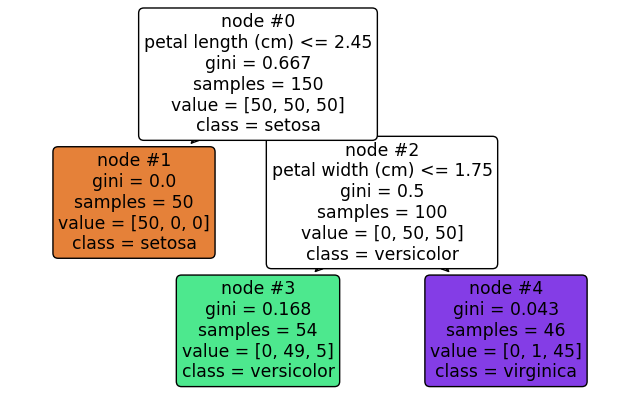

By hand: [0.    0.907 0.093]
Leaf value from tree: [[0.    0.907 0.093]]


In [5]:
# TODO 2: your code here
flowers = [[1.4, 0.2], [5.0, 1.5], [6.0, 1.7]]

probas = tree_clf.predict_proba(flowers)
preds  = tree_clf.predict(flowers)
leaves = tree_clf.apply(flowers)

for f, p, c, leaf in zip(flowers, probas, preds, leaves):
    print(f"Flower {f}: probs={p.round(3)}  prediction={iris.target_names[c]}  leaf_id={leaf}")

# Draw the tree again so the value counts are visible
plt.figure(figsize=(8, 5))
plot_tree(tree_clf, feature_names=iris.feature_names[2:],
          class_names=iris.target_names, rounded=True, filled=True, node_ids=True)
plt.show()

# 3) Hand check for [5.0, 1.5]:
# petal length 5.0 > 2.45 -> right branch; petal width 1.5 <= 1.75 -> leaf with value = [0, 49, 5]
counts = np.array([0, 49, 5])
print("By hand:", (counts / counts.sum()).round(3))   # [0, 49/54, 5/54] = [0, 0.907, 0.093]
print("Leaf value from tree:", tree_clf.tree_.value[leaves[1]].round(3))

*Your reflection:*

Both `[5.0, 1.5]` and `[6.0, 1.7]` have petal length > 2.45 and petal width ≤ 1.75, so they land in the same leaf (value `[0, 49, 5]`) and get the same probabilities: 49/54 ≈ 0.907 Versicolor and 5/54 ≈ 0.093 Virginica. A tree only knows which region a point falls into, not where it is inside the region. That makes it simple and easy to interpret (a strength), but it's also a weakness: the probabilities are coarse and don't reflect that `[6.0, 1.7]` is closer to the decision boundary and probably more likely to be Virginica.

## Part 3: Gini vs. Entropy
The function below computes Gini impurity for a list of class counts (e.g., a node's `value`).

In [6]:
def gini(counts):
    counts = np.array(counts, dtype=float)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

print("Root  [50, 50, 50]:", round(gini([50, 50, 50]), 3))
print("Green [0, 49, 5]:  ", round(gini([0, 49, 5]), 3))

Root  [50, 50, 50]: 0.667
Green [0, 49, 5]:   0.168


### TODO 3
1. Write a function `entropy(counts)` using $H = -\sum p_i \log_2 p_i$ (skip classes with $p_i = 0$). Compute it for the same two nodes.
2. Train a second tree with `criterion="entropy"` (`max_depth=2`) and plot it. Compare it to the Gini tree: are the splits the same?

**Reflection:** The textbook says Gini "tends to isolate the most frequent class in its own branch," while entropy produces "slightly more balanced trees." Did you see a difference on Iris? Why might the difference be small here?

Root  [50, 50, 50] entropy: 1.585
Green [0, 49, 5]   entropy: 0.445


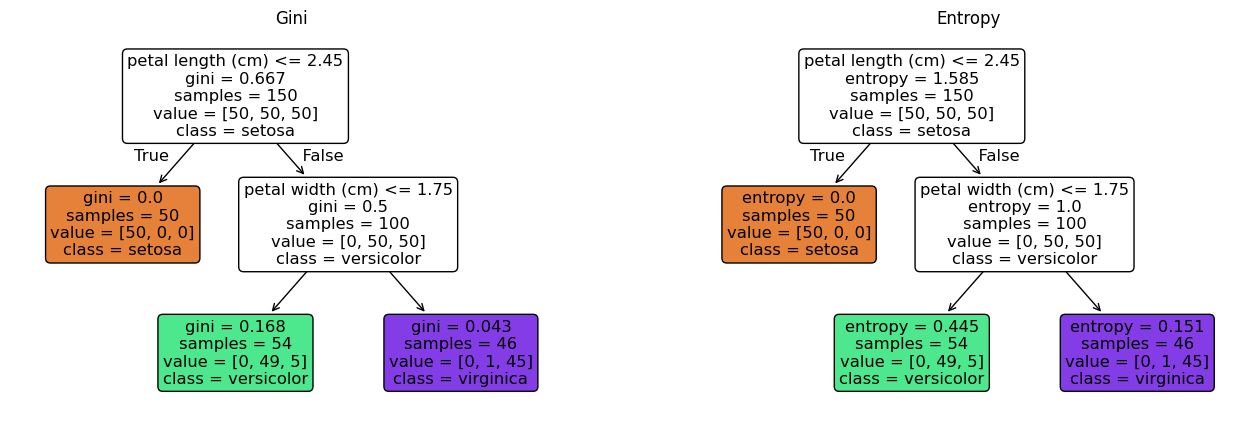

Gini     splits: [('petal length (cm)', np.float64(2.45)), ('petal width (cm)', np.float64(1.75))]
Entropy  splits: [('petal length (cm)', np.float64(2.45)), ('petal width (cm)', np.float64(1.75))]
Same predictions on all Iris samples? True


In [7]:
# TODO 3: your code here
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts / counts.sum()
    p = p[p > 0]                      # skip classes with p = 0
    return -np.sum(p * np.log2(p))

print("Root  [50, 50, 50] entropy:", round(entropy([50, 50, 50]), 3))
print("Green [0, 49, 5]   entropy:", round(entropy([0, 49, 5]), 3))

# Entropy tree
tree_ent = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=42).fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_tree(tree_clf, feature_names=iris.feature_names[2:], class_names=iris.target_names,
          rounded=True, filled=True, ax=axes[0])
axes[0].set_title("Gini")
plot_tree(tree_ent, feature_names=iris.feature_names[2:], class_names=iris.target_names,
          rounded=True, filled=True, ax=axes[1])
axes[1].set_title("Entropy")
plt.show()

# Compare the splits directly
for name, t in [("Gini", tree_clf), ("Entropy", tree_ent)]:
    splits = [(iris.feature_names[2:][f], round(th, 2))
              for f, th in zip(t.tree_.feature, t.tree_.threshold) if f >= 0]
    print(f"{name:<8} splits: {splits}")
print("Same predictions on all Iris samples?", np.array_equal(tree_clf.predict(X), tree_ent.predict(X)))

*Your reflection:*

The root has entropy log₂(3) ≈ 1.585 and the green node [0, 49, 5] has entropy ≈ 0.445 (vs. gini 0.667 and 0.168). On Iris, both criteria picked exactly the same splits (petal length ≤ 2.45, then petal width ≤ 1.75), so there was no visible difference. The difference is small here because Setosa is perfectly separable, so any reasonable impurity measure will isolate it first, and the remaining classes are only split by one obvious threshold. Gini and entropy are closely related curves, so they usually only disagree on harder, noisier or more imbalanced datasets.

## Part 4: Regularization and overfitting (Moons dataset)
The code trains an **unrestricted** tree on a noisy dataset and compares train vs. test accuracy.

No restrictions           train=1.000  test=0.856  leaves=31


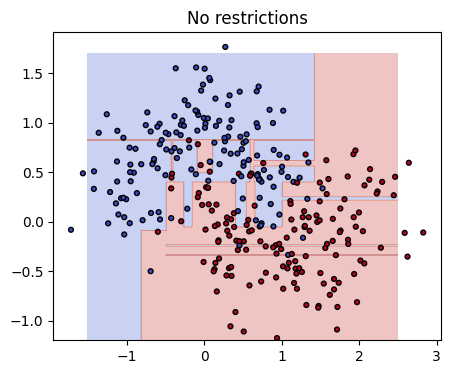

In [8]:
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=42)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.3, random_state=42)

def evaluate(model, name):
    model.fit(Xm_train, ym_train)
    tr = accuracy_score(ym_train, model.predict(Xm_train))
    te = accuracy_score(ym_test,  model.predict(Xm_test))
    print(f"{name:<25} train={tr:.3f}  test={te:.3f}  leaves={model.get_n_leaves()}")

def plot_boundary(model, title):
    x0, x1 = np.meshgrid(np.linspace(-1.5, 2.5, 300), np.linspace(-1.2, 1.7, 300))
    Z = model.predict(np.c_[x0.ravel(), x1.ravel()]).reshape(x0.shape)
    plt.contourf(x0, x1, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(Xm[:, 0], Xm[:, 1], c=ym, s=12, cmap="coolwarm", edgecolor="k")
    plt.title(title)

deep_tree = DecisionTreeClassifier(random_state=42)
evaluate(deep_tree, "No restrictions")

plt.figure(figsize=(5, 4))
plot_boundary(deep_tree, "No restrictions")
plt.show()

### TODO 4
1. Train a regularized tree with `min_samples_leaf=5`. Evaluate it and plot its decision boundary **next to** the unrestricted one (use `plt.subplot`).
2. Write a loop that tries `max_depth` from 1 to 12 and **plots train and test accuracy vs. depth** on one chart. Which depth gives the best test accuracy?
3. Try one other regularization hyperparameter from the slides (`max_leaf_nodes`, `min_samples_split`, or `max_features`) and report its effect.

**Reflection:** Decision trees are called *nonparametric*. Explain what that means and how it relates to the overfitting you observed.

min_samples_leaf=5        train=0.938  test=0.889  leaves=19


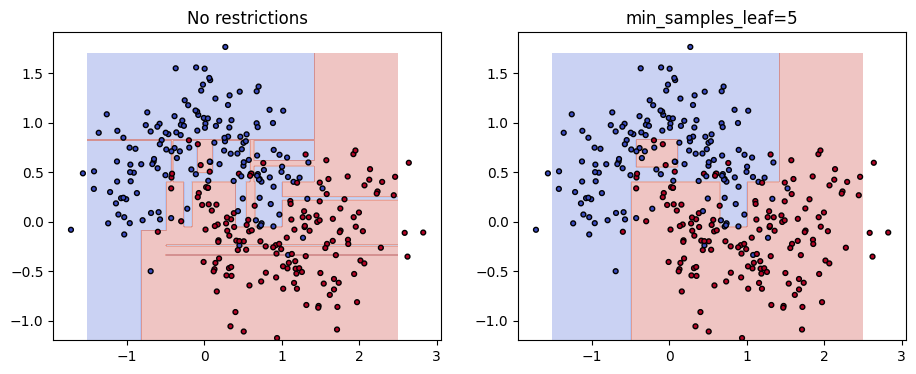

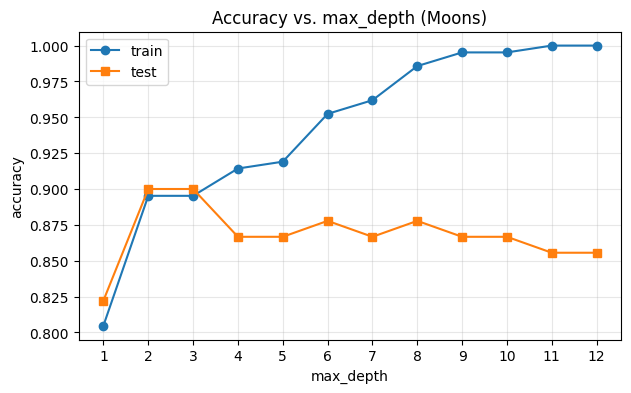

Best max_depth = 2 with test accuracy = 0.900
max_leaf_nodes=4          train=0.895  test=0.900  leaves=4
max_leaf_nodes=8          train=0.929  test=0.900  leaves=8
max_leaf_nodes=16         train=0.962  test=0.900  leaves=16
max_leaf_nodes=32         train=1.000  test=0.833  leaves=31
max_leaf_nodes=None       train=1.000  test=0.856  leaves=31


In [9]:
# TODO 4: your code here
# 1) Regularized tree vs. unrestricted, side by side
reg_tree = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
evaluate(reg_tree, "min_samples_leaf=5")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plot_boundary(deep_tree, "No restrictions")
plt.subplot(1, 2, 2)
plot_boundary(reg_tree, "min_samples_leaf=5")
plt.show()

# 2) Train / test accuracy vs. max_depth
depths = range(1, 13)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xm_train, ym_train)
    train_acc.append(accuracy_score(ym_train, m.predict(Xm_train)))
    test_acc.append(accuracy_score(ym_test,  m.predict(Xm_test)))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, "o-", label="train")
plt.plot(depths, test_acc,  "s-", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.xticks(depths)
plt.title("Accuracy vs. max_depth (Moons)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

best_d = depths[int(np.argmax(test_acc))]
print(f"Best max_depth = {best_d} with test accuracy = {max(test_acc):.3f}")

# 3) Another regularization hyperparameter: max_leaf_nodes
for n in [4, 8, 16, 32, None]:
    evaluate(DecisionTreeClassifier(max_leaf_nodes=n, random_state=42), f"max_leaf_nodes={n}")

*Your reflection:*

"Nonparametric" doesn't mean the tree has no parameters; it means the number of parameters (splits and leaves) isn't fixed before training, so the model's structure grows to fit the data. Left unrestricted, the tree kept splitting until it hit 100% train accuracy with 31 leaves, but test accuracy was only about 0.856 because it memorized the noise. Regularization limits that freedom: `min_samples_leaf=5` lowered train accuracy to about 0.938 but raised test accuracy to about 0.889, and `max_depth=2` or `3` gave the best test accuracy (0.900). `max_leaf_nodes` between 4 and 16 also kept test accuracy at 0.900, while 32 leaves overfit again.

## Part 5: Decision tree regression
The code fits a regression tree to noisy quadratic data.

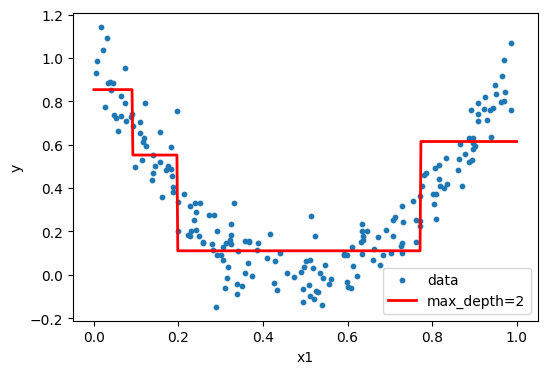

In [10]:
rng = np.random.RandomState(42)
Xr = rng.rand(200, 1)
yr = 4 * (Xr[:, 0] - 0.5) ** 2 + rng.randn(200) / 10

tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(Xr, yr)

x_plot = np.linspace(0, 1, 500).reshape(-1, 1)
plt.figure(figsize=(6, 4))
plt.scatter(Xr, yr, s=10, label="data")
plt.plot(x_plot, tree_reg.predict(x_plot), "r-", linewidth=2, label="max_depth=2")
plt.xlabel("x1"); plt.ylabel("y"); plt.legend()
plt.show()

### TODO 5
1. Predict the value for **x1 = 0.6** (the question from the slides). Then plot the tree with `plot_tree` and confirm the prediction equals the `value` in the leaf it lands in.
2. Add two more lines to the plot: `max_depth=3` and a tree with **no restrictions**.
3. Add a tree with `min_samples_leaf=10` to the plot and compare it to the unrestricted tree.

**Reflection:** A regression tree predicts the **average** of the training targets in a leaf. Which impurity measure does it minimize instead of Gini, and why does the unrestricted tree look so jagged?

Prediction for x1=0.6: [0.1106]
Leaf id: 5 | leaf value: [0.1106]


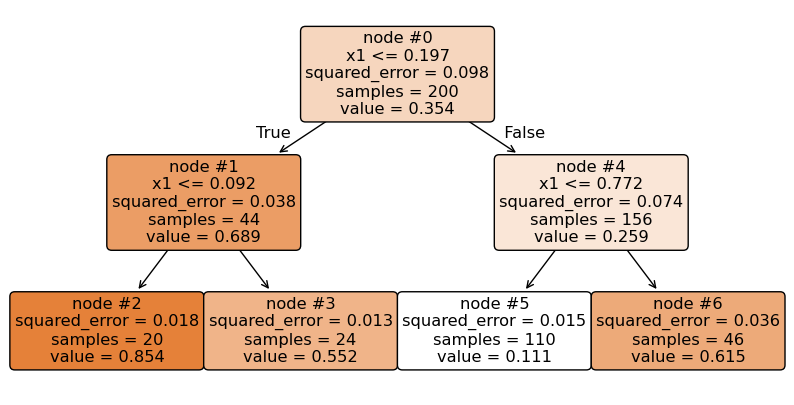

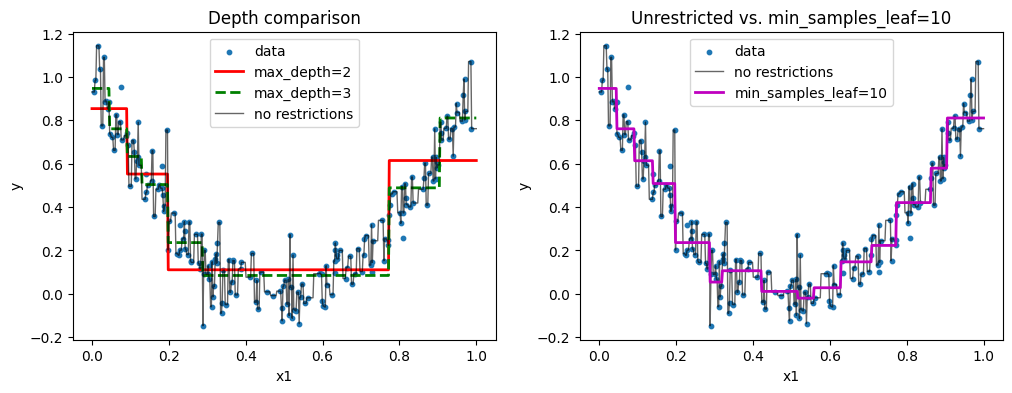

Leaves  -> depth2: 4 | depth3: 8 | unrestricted: 200 | min_samples_leaf=10: 15


In [11]:
# TODO 5: your code here
# 1) Predict x1 = 0.6 and confirm it matches the leaf value
pred = tree_reg.predict([[0.6]])
leaf = tree_reg.apply([[0.6]])[0]
print("Prediction for x1=0.6:", pred.round(4))
print("Leaf id:", leaf, "| leaf value:", tree_reg.tree_.value[leaf].ravel().round(4))

plt.figure(figsize=(10, 5))
plot_tree(tree_reg, feature_names=["x1"], rounded=True, filled=True, node_ids=True)
plt.show()

# 2) + 3) Compare several regression trees
tree_reg3    = DecisionTreeRegressor(max_depth=3, random_state=42).fit(Xr, yr)
tree_regfull = DecisionTreeRegressor(random_state=42).fit(Xr, yr)
tree_reg10   = DecisionTreeRegressor(min_samples_leaf=10, random_state=42).fit(Xr, yr)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(Xr, yr, s=10, label="data")
plt.plot(x_plot, tree_reg.predict(x_plot),  "r-",  linewidth=2, label="max_depth=2")
plt.plot(x_plot, tree_reg3.predict(x_plot), "g--", linewidth=2, label="max_depth=3")
plt.plot(x_plot, tree_regfull.predict(x_plot), "k-", linewidth=1, alpha=0.6, label="no restrictions")
plt.xlabel("x1"); plt.ylabel("y"); plt.legend(); plt.title("Depth comparison")

plt.subplot(1, 2, 2)
plt.scatter(Xr, yr, s=10, label="data")
plt.plot(x_plot, tree_regfull.predict(x_plot), "k-", linewidth=1, alpha=0.6, label="no restrictions")
plt.plot(x_plot, tree_reg10.predict(x_plot), "m-", linewidth=2, label="min_samples_leaf=10")
plt.xlabel("x1"); plt.ylabel("y"); plt.legend(); plt.title("Unrestricted vs. min_samples_leaf=10")
plt.show()

print("Leaves  -> depth2:", tree_reg.get_n_leaves(), "| depth3:", tree_reg3.get_n_leaves(),
      "| unrestricted:", tree_regfull.get_n_leaves(), "| min_samples_leaf=10:", tree_reg10.get_n_leaves())

*Your reflection:*

For x1 = 0.6 the tree goes right at x1 > 0.197, then left at x1 ≤ 0.772, landing in a leaf with value ≈ 0.111, which is exactly what `predict` returned. Instead of Gini, a regression tree minimizes the **mean squared error (MSE)** of each split, so each leaf's best prediction is the average of its training targets. The unrestricted tree keeps splitting until each leaf holds about one sample, so it follows every noisy point and the line becomes jagged (overfitting). `min_samples_leaf=10` forces each leaf to average at least 10 points, which gives a smoother step function that follows the quadratic shape instead of the noise.

## Part 6: Instability
Decision trees are sensitive to small changes in the training data. The code trains a tree on Iris and prints its root split.

In [12]:
tree_a = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)
print("Root split: feature =", iris.feature_names[2:][tree_a.tree_.feature[0]],
      "| threshold =", round(tree_a.tree_.threshold[0], 2))

Root split: feature = petal length (cm) | threshold = 2.45


### TODO 6
1. Remove the **widest Iris-Versicolor** flower from the data (hint: `(X[:, 1] == X[:, 1][y == 1].max()) & (y == 1)`), retrain, and plot the new tree. What changed?
2. Rotate the Iris data by 45° (code below) and train a tree on it. Compare the number of leaves needed with the original tree.

```python
angle = np.pi / 4
R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
X_rot = X.dot(R)
```

**Reflection:** Why are decision trees sensitive to rotation? Name one technique (covered later in the course) that reduces this instability.

Removed flower(s): [[4.8 1.8]]


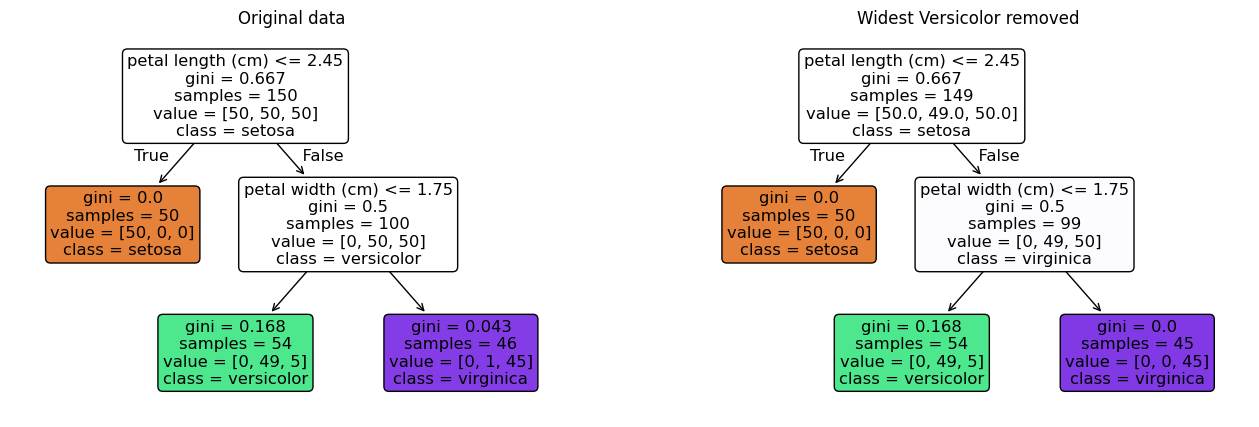

New root split: feature = petal length (cm) | threshold = 2.45
random_state=0: root = petal width (cm) <= 0.80
random_state=1: root = petal width (cm) <= 0.80
random_state=2: root = petal length (cm) <= 2.45
random_state=3: root = petal length (cm) <= 2.45
max_depth=2: original leaves=3 (depth 2) | rotated leaves=3 (depth 2)
max_depth=None: original leaves=8 (depth 5) | rotated leaves=9 (depth 5)


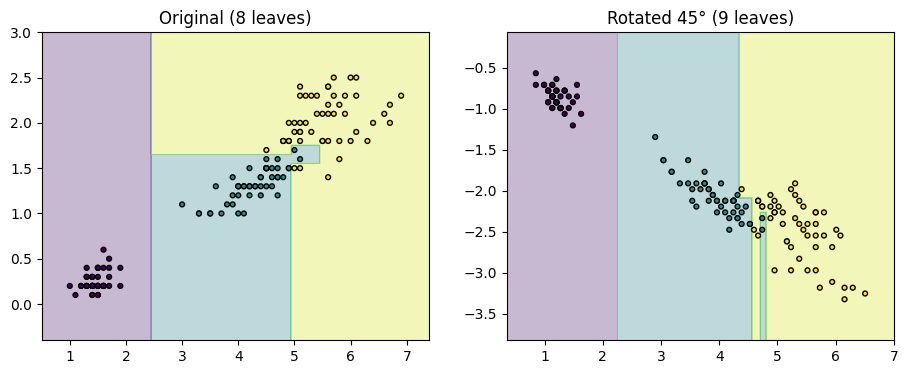

In [13]:
# TODO 6: your code here
# 1) Remove the widest Iris-Versicolor and retrain
mask = (X[:, 1] == X[:, 1][y == 1].max()) & (y == 1)
print("Removed flower(s):", X[mask])
X_tweak, y_tweak = X[~mask], y[~mask]

tree_b = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_tweak, y_tweak)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_tree(tree_a, feature_names=iris.feature_names[2:], class_names=iris.target_names,
          rounded=True, filled=True, ax=axes[0]); axes[0].set_title("Original data")
plot_tree(tree_b, feature_names=iris.feature_names[2:], class_names=iris.target_names,
          rounded=True, filled=True, ax=axes[1]); axes[1].set_title("Widest Versicolor removed")
plt.show()

print("New root split: feature =", iris.feature_names[2:][tree_b.tree_.feature[0]],
      "| threshold =", round(tree_b.tree_.threshold[0], 2))

# Extra: same data, only random_state changes -> the root split can still change
for rs in range(4):
    t = DecisionTreeClassifier(max_depth=2, random_state=rs).fit(X, y)
    print(f"random_state={rs}: root = {iris.feature_names[2:][t.tree_.feature[0]]} "
          f"<= {t.tree_.threshold[0]:.2f}")

# 2) Rotate the data by 45 degrees
angle = np.pi / 4
R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
X_rot = X.dot(R)

for d in [2, None]:
    t_orig = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X, y)
    t_rot  = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_rot, y)
    print(f"max_depth={d}: original leaves={t_orig.get_n_leaves()} (depth {t_orig.get_depth()}) | "
          f"rotated leaves={t_rot.get_n_leaves()} (depth {t_rot.get_depth()})")

tree_rot = DecisionTreeClassifier(random_state=42).fit(X_rot, y)
tree_orig = DecisionTreeClassifier(random_state=42).fit(X, y)

def iris_boundary(model, data, title):
    x0, x1 = np.meshgrid(np.linspace(data[:, 0].min() - 0.5, data[:, 0].max() + 0.5, 300),
                         np.linspace(data[:, 1].min() - 0.5, data[:, 1].max() + 0.5, 300))
    Z = model.predict(np.c_[x0.ravel(), x1.ravel()]).reshape(x0.shape)
    plt.contourf(x0, x1, Z, alpha=0.3, cmap="viridis")
    plt.scatter(data[:, 0], data[:, 1], c=y, s=12, cmap="viridis", edgecolor="k")
    plt.title(title)

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1); iris_boundary(tree_orig, X, f"Original ({tree_orig.get_n_leaves()} leaves)")
plt.subplot(1, 2, 2); iris_boundary(tree_rot, X_rot, f"Rotated 45° ({tree_rot.get_n_leaves()} leaves)")
plt.show()

*Your reflection:*

In this run, removing the widest Versicolor (4.8 cm × 1.8 cm) didn't change the split thresholds; only the right-most leaf changed from `[0, 1, 45]` to a pure `[0, 0, 45]`. The textbook shows the tree changing a lot, but here the instability showed up another way: with the *same* data, just changing `random_state` flips the root between petal length ≤ 2.45 and petal width ≤ 0.8, because both splits tie. When rotated 45°, the unrestricted tree needed 9 leaves instead of 8, and its boundary becomes a staircase. Trees are sensitive to rotation because they only make axis-aligned (perpendicular) splits, so a diagonal boundary has to be approximated with many small steps. **Random Forests** (averaging many trees trained on different samples/features) reduce this instability; PCA before training can also help with rotation.

## Bonus (optional)
Use `GridSearchCV` to tune `max_depth`, `min_samples_leaf`, and `max_leaf_nodes` on the Moons data with 5-fold cross-validation. Report the best parameters and test accuracy. Can you beat the best single hyperparameter from Part 4?

Best params: {'max_depth': None, 'max_leaf_nodes': 12, 'min_samples_leaf': 2}
Best CV accuracy: 0.871
Test accuracy:    0.911  (best single hyperparameter in Part 4: 0.900)


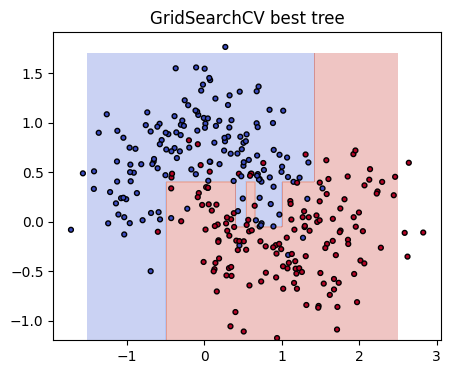

In [14]:
# Bonus: your code here
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth":        [None, 2, 3, 4, 5, 6, 8],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_leaf_nodes":   [None, 4, 8, 12, 16, 24, 32],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, n_jobs=-1)
grid.fit(Xm_train, ym_train)

print("Best params:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")
test_acc_best = accuracy_score(ym_test, grid.best_estimator_.predict(Xm_test))
print(f"Test accuracy:    {test_acc_best:.3f}  (best single hyperparameter in Part 4: 0.900)")

plt.figure(figsize=(5, 4))
plot_boundary(grid.best_estimator_, "GridSearchCV best tree")
plt.show()

*Bonus result:* GridSearchCV picked `max_leaf_nodes=12`, `min_samples_leaf=2` (no depth limit) with CV accuracy ≈ 0.871 and test accuracy ≈ 0.911, slightly beating the best single hyperparameter from Part 4 (0.900). With only 90 test samples, that's one extra correct prediction, so the gain is small.